In [5]:
import csv
from pathlib import Path

ROOT = Path(r"C:\nutrition5k")

def read_dishes(csv_path):
    dishes = {}
    with open(csv_path, newline="") as f:
        for row in csv.reader(f):
            dish_id = row[0]
            totals = dict(zip(
                ["kcal", "mass_g", "fat_g", "carb_g", "protein_g"],
                map(float, row[1:6])
            ))
            ingredients = []
            for i in range(6, len(row), 7):      # bloques de 7 columnas
                block = row[i:i + 7]
                if len(block) < 7:
                    break
                ingredients.append({
                    "id": block[0],
                    "name": block[1],
                    "grams": float(block[2]),
                })
            dishes[dish_id] = {"totals": totals, "ingredients": ingredients}
    return dishes

## **Cuantas platos tienen foto y metadatos**

In [6]:
dishes = {}
for name in ["dish_metadata_cafe1.csv", "dish_metadata_cafe2.csv"]:
    dishes.update(read_dishes(ROOT / "metadata" / name))

image_dirs = {p.name for p in (ROOT / "realsense_overhead").iterdir() if p.is_dir()}

print("platos en metadata:", len(dishes))
print("carpetas con imagen:", len(image_dirs))
print("platos con ambos:", len(set(dishes) & image_dirs))

platos en metadata: 5006
carpetas con imagen: 3490
platos con ambos: 3490


In [18]:
from collections import Counter, defaultdict

usable = sorted(set(dishes) & image_dirs)

freq = Counter()                 # en cuántos platos aparece cada ingrediente
total_g = defaultdict(float)     # gramos acumulados

for d in usable:
    for ing in dishes[d]["ingredients"]:
        freq[ing["name"]] += 1
        total_g[ing["name"]] += ing["grams"]

print("ingredientes distintos:", len(freq))
print()
for name, n in freq.most_common(40):
        print(f"{name:25s} platos={n:5d}  g_promedio={total_g[name]/n:6.1f}")

ingredientes distintos: 241

olive oil                 platos= 1639  g_promedio=   4.6
salt                      platos= 1460  g_promedio=   0.5
garlic                    platos=  976  g_promedio=   1.2
pepper                    platos=  728  g_promedio=   1.4
vinegar                   platos=  727  g_promedio=   2.3
onions                    platos=  721  g_promedio=   7.4
lemon juice               platos=  595  g_promedio=   1.4
arugula                   platos=  514  g_promedio=  17.9
parsley                   platos=  503  g_promedio=   0.9
cherry tomatoes           platos=  483  g_promedio=  30.4
carrot                    platos=  447  g_promedio=  34.8
spinach (raw)             platos=  446  g_promedio=  20.3
broccoli                  platos=  418  g_promedio=  52.2
shallots                  platos=  410  g_promedio=   2.5
mustard                   platos=  377  g_promedio=   0.5
cucumbers                 platos=  343  g_promedio=  19.2
mixed greens              platos=  320  g_p

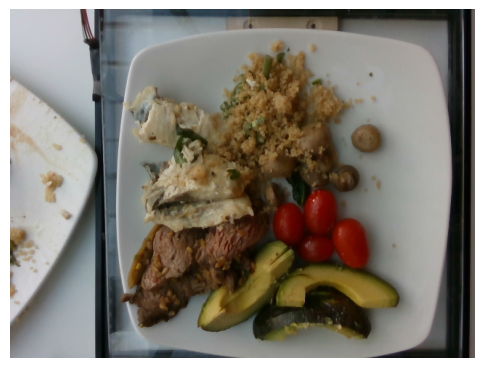

avocado                      90.0 g
salmon                       86.3 g
beef                         55.0 g
tomatoes                     44.0 g
mushroom                     39.0 g
quinoa                       35.0 g
brown rice                   17.3 g
millet                        7.3 g
shallots                      6.3 g
spinach (raw)                 4.3 g
onions                        3.6 g
garlic                        2.6 g
olive oil                     2.1 g
spinach (cooked)              1.8 g
bok choy                      1.8 g
jalapenos                     0.9 g
lemon juice                   0.9 g
cilantro                      0.9 g
ginger                        0.4 g
salt                          0.3 g
chili                         0.2 g
lime                          0.1 g
vinegar                       0.1 g


In [25]:
import matplotlib.pyplot as plt
from PIL import Image

def show_dish(dish_id):
    img = Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png")
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()
    for ing in sorted(dishes[dish_id]["ingredients"], key=lambda x: -x["grams"]):
        print(f"{ing['name']:25s} {ing['grams']:7.1f} g")

show_dish(usable[3200])

# Vocabulario con reglas

In [ ]:
EXCLUDE = {
    "olive oil", "salt", "pepper", "vinegar", "lemon juice", "mustard",
    "garlic", "thyme", "parsley", "cilantro", "shallots", "jalapenos",
    "lime", "sugar", "soy sauce",
}

MERGE = {
    "white rice": "rice", "brown rice": "rice",
    "arugula": "leafy greens", "spinach (raw)": "leafy greens",
    "kale": "leafy greens", "chard": "leafy greens",
    "mixed greens": "leafy greens", "bok choy": "leafy greens",
    
}

MIN_G = 10

def segmentable(dish_id):
    """Devuelve {clase: gramos} solo con lo que vale la pena segmentar."""
    out = {}
    for ing in dishes[dish_id]["ingredients"]:
        name = ing["name"]
        if name in EXCLUDE or ing["grams"] < MIN_G:
            continue
        label = MERGE.get(name, name)
        out[label] = out.get(label, 0) + ing["grams"]
    return out

In [78]:
MERGE.update({
    "lettuce": "leafy greens",
    "chicken thighs": "chicken",
    "pepperoni pizza": "cheese pizza",
})

In [27]:
label_freq = Counter()
n_labels = Counter()          # cuántos platos tienen 0, 1, 2, 3... clases

for d in usable:
    seg = segmentable(d)
    n_labels[len(seg)] += 1
    for label in seg:
        label_freq[label] += 1

print("clases resultantes:", len(label_freq))
print("platos por número de clases:", dict(sorted(n_labels.items())))
print()
for label, n in label_freq.most_common(30):
    print(f"{label:25s} platos={n}")

clases resultantes: 192
platos por número de clases: {0: 20, 1: 1154, 2: 579, 3: 574, 4: 491, 5: 318, 6: 184, 7: 93, 8: 55, 9: 12, 10: 7, 12: 3}

leafy greens              platos=845
broccoli                  platos=344
rice                      platos=337
chicken                   platos=312
cheese pizza              platos=262
carrot                    platos=252
cauliflower               platos=247
scrambled eggs            platos=229
cherry tomatoes           platos=221
bacon                     platos=201
sweet potato              platos=197
fish                      platos=187
caesar salad              platos=185
berries                   platos=181
pork                      platos=181
egg whites                platos=179
cucumbers                 platos=177
beef                      platos=173
roasted potatoes          platos=171
olives                    platos=169
wheat berry               platos=168
pineapple                 platos=160
squash                    platos=153
bru

# Selección muestras (NO aleatorio)

In [28]:
import random
random.seed(0)

by_nclasses = defaultdict(list)
for d in usable:
    by_nclasses[len(segmentable(d))].append(d)

pilot = []

# 40 platos de 1 clase, máx. 2 por clase para no llenarlo de leafy greens
single_by_label = defaultdict(list)
for d in by_nclasses[1]:
    label = next(iter(segmentable(d)))
    single_by_label[label].append(d)

labels = list(single_by_label)
random.shuffle(labels)
for label in labels:
    pilot += random.sample(single_by_label[label], min(2, len(single_by_label[label])))
    if len(pilot) >= 40:
        break

# 30 platos de 2-3 clases, 15 de 4-5, 10 de 6+
for rng, k in [((2, 3), 30), ((4, 5), 15), ((6, 12), 10)]:
    pool = [d for n in range(rng[0], rng[1] + 1) for d in by_nclasses[n]]
    pilot += random.sample(pool, k)

print(len(pilot), "platos en el piloto")

96 platos en el piloto


In [30]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_arch_list())

2.11.0+cu128
True
NVIDIA GeForce RTX 5060 Laptop GPU
['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


# YOLo

vocabulario: ['potatoes']
gramos: {'potatoes': 74.0}
  potatoes             conf=0.22
  potatoes             conf=0.22
  potatoes             conf=0.18
  potatoes             conf=0.09
  potatoes             conf=0.06


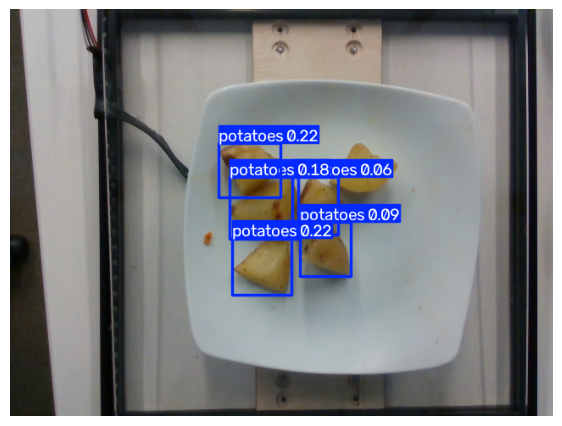

In [41]:
from ultralytics import YOLOWorld
import matplotlib.pyplot as plt

model = YOLOWorld("yolov8s-worldv2.pt")   # se descarga la primera vez

def detect_dish(dish_id, conf=0.1):
    classes = list(segmentable(dish_id).keys())
    model.set_classes(classes)
    img_path = ROOT / "realsense_overhead" / dish_id / "rgb.png"
    result = model.predict(str(img_path), conf=conf, verbose=False)[0]
    return classes, result

def show_detection(dish_id, conf=0.05):
    classes, r = detect_dish(dish_id, conf)
    print("vocabulario:", classes)
    print("gramos:", segmentable(dish_id))
    for b in r.boxes:
        print(f"  {classes[int(b.cls)]:20s} conf={float(b.conf):.2f}")
    plt.figure(figsize=(7, 7))
    plt.imshow(r.plot()[:, :, ::-1])   # plot() devuelve BGR, lo pasamos a RGB
    plt.axis("off")
    plt.show()

show_detection(pilot[0])

In [81]:
show_detection(pilot[12])

vocabulario: ['dumplings']
gramos: {'dumplings': 68.0}


C:\Users\mjcor\AppData\Local\Temp\ipykernel_26992\2573950775.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# SAM

imagen: (480, 640, 3) | máscaras: (14, 480, 640)
ingredientes: {'potatoes': 74.0}


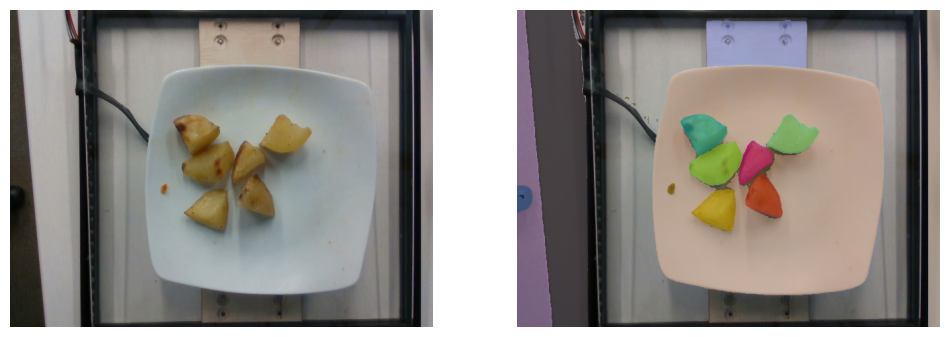

imagen: (480, 640, 3) | máscaras: (6, 480, 640)
ingredientes: {'cheese pizza': 39.0, 'beef': 82.468979, 'millet': 10.995864}


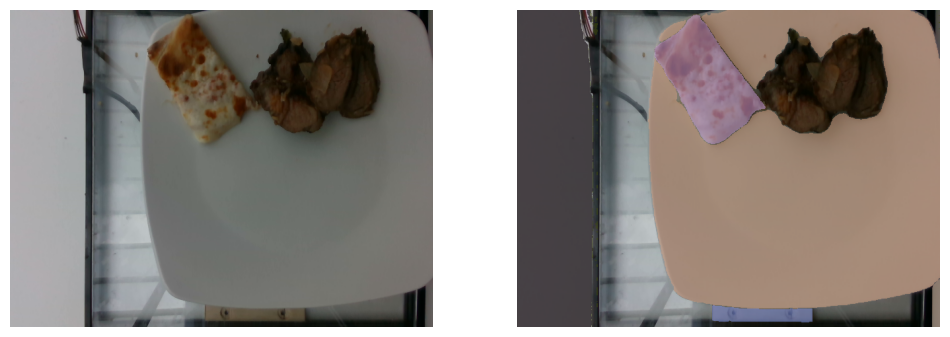

imagen: (480, 640, 3) | máscaras: (16, 480, 640)
ingredientes: {'zucchini': 45.5, 'cheese pizza': 35.0, 'beef': 57.270126, 'chayote squash': 45.5}


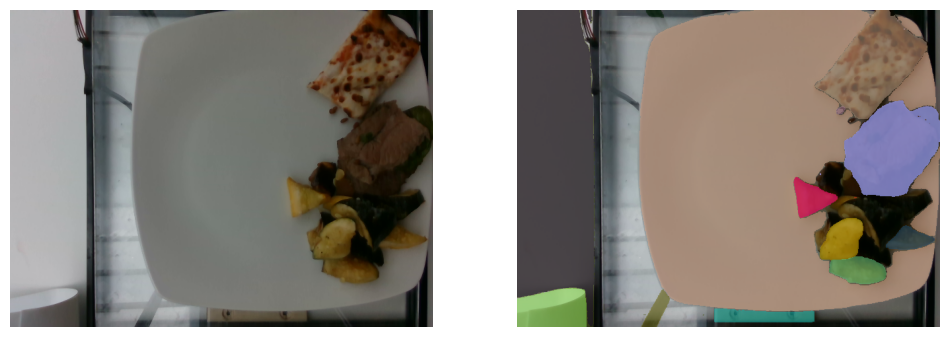

imagen: (480, 640, 3) | máscaras: (18, 480, 640)
ingredientes: {'chicken': 124.987068, 'tomatillo': 10.529801, 'roasted potatoes': 53.0, 'olives': 15.0, 'caesar salad': 77.0, 'quinoa': 21.059603, 'fish': 105.298012, 'tomatoes': 95.0, 'rice': 12.498706}


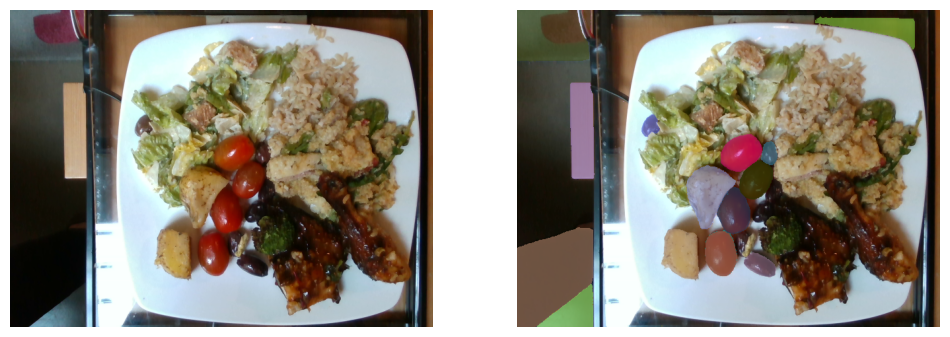

In [46]:
from ultralytics import SAM
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

sam = SAM("sam2.1_b.pt")      # se descarga la primera vez

def auto_masks(dish_id):
    img_path = str(ROOT / "realsense_overhead" / dish_id / "rgb.png")
    r = sam(img_path, verbose=False)[0]
    masks = r.masks.data.cpu().numpy().astype(bool)    # (N, H, W)
    return img_path, masks

def show_masks(dish_id):
    img_path, masks = auto_masks(dish_id)
    img = np.array(Image.open(img_path).convert("RGB"))
    print("imagen:", img.shape, "| máscaras:", masks.shape)
    print("ingredientes:", segmentable(dish_id))

    # pintamos de la más grande a la más pequeña para que las pequeñas queden visibles
    overlay = img.astype(float)
    rng = np.random.default_rng(0)
    for m in sorted(masks, key=lambda m: -m.sum()):
        color = rng.integers(0, 255, 3)
        overlay[m] = 0.5 * overlay[m] + 0.5 * color

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img);                     ax[0].axis("off")
    ax[1].imshow(overlay.astype(np.uint8)); ax[1].axis("off")
    plt.show()

# aprox.: 1 clase, 2-3 clases, 4-5 clases, 6+ clases
for i in [0, 45, 75, 90]:
    show_masks(pilot[i])

In [50]:
def auto_masks(dish_id):
    img_path = str(ROOT / "realsense_overhead" / dish_id / "rgb.png")
    r = sam(img_path, verbose=False)[0]
    masks = r.masks.data.cpu().numpy().astype(bool)
    return img_path, masks

In [51]:
import inspect
from functools import partial

# 1. Una llamada cualquiera para que ultralytics cree el predictor interno
sam(str(ROOT / "realsense_overhead" / pilot[0] / "rgb.png"), verbose=False)

# 2. Mira qué parámetros acepta generate en TU versión
print(inspect.signature(sam.predictor.generate))

(im, crop_n_layers=0, crop_overlap_ratio=0.3413333333333333, crop_downscale_factor=1, point_grids=None, points_stride=32, points_batch_size=64, conf_thres=0.88, stability_score_thresh=0.95, stability_score_offset=0.95, crop_nms_thresh=0.7, min_mask_region_area=0)


In [52]:
def set_sam_params(**params):
    gen = sam.predictor.__class__.generate
    sam.predictor.generate = partial(gen, sam.predictor, **params)

set_sam_params(points_stride=48, conf_thres=0.75, stability_score_thresh=0.85)

imagen: (480, 640, 3) | máscaras: (27, 480, 640)
ingredientes: {'potatoes': 74.0}


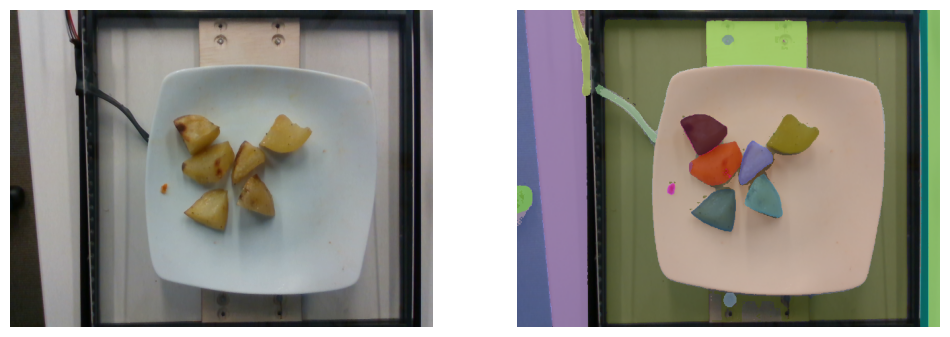

imagen: (480, 640, 3) | máscaras: (25, 480, 640)
ingredientes: {'cheese pizza': 39.0, 'beef': 82.468979, 'millet': 10.995864}


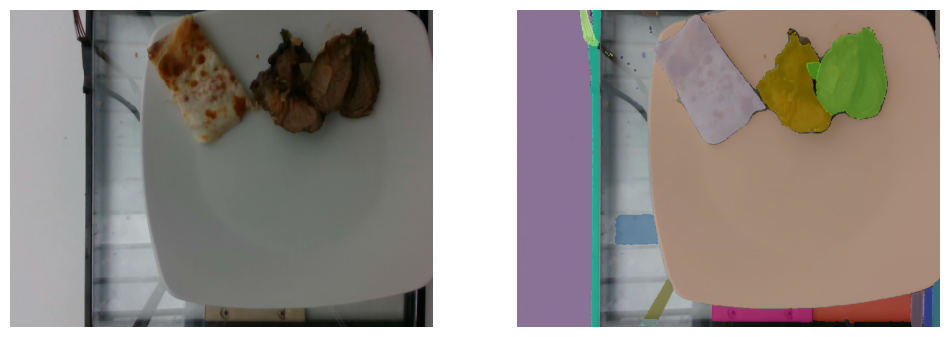

imagen: (480, 640, 3) | máscaras: (43, 480, 640)
ingredientes: {'zucchini': 45.5, 'cheese pizza': 35.0, 'beef': 57.270126, 'chayote squash': 45.5}


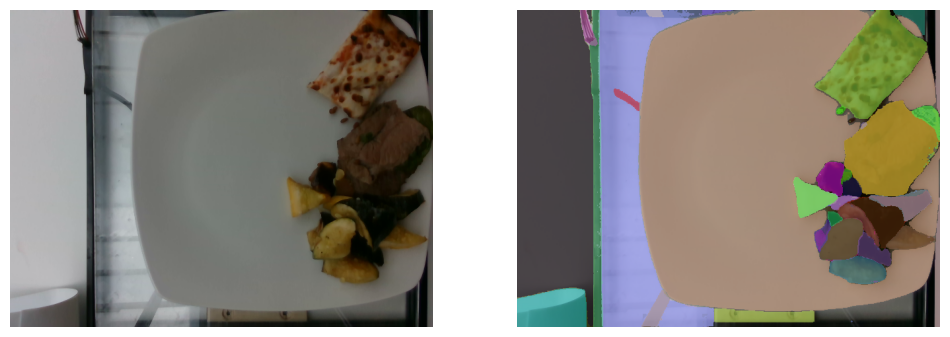

imagen: (480, 640, 3) | máscaras: (60, 480, 640)
ingredientes: {'chicken': 124.987068, 'tomatillo': 10.529801, 'roasted potatoes': 53.0, 'olives': 15.0, 'caesar salad': 77.0, 'quinoa': 21.059603, 'fish': 105.298012, 'tomatoes': 95.0, 'rice': 12.498706}


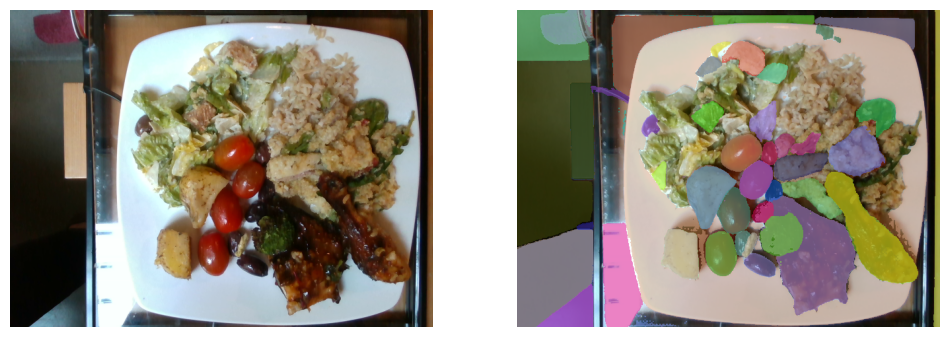

In [53]:
for i in [0, 45, 75, 90]:
    show_masks(pilot[i])

# Uso del modelo fodsegmenter

In [56]:
import torch
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation

SEG_PATH = r"C:\foodseg_segformer\mit-b1"
device = "cuda"

seg = SegformerForSemanticSegmentation.from_pretrained(SEG_PATH).to(device).eval()

print("num_labels:", seg.config.num_labels)
print("clase 0:", seg.config.id2label.get(0))

c:\Users\mjcor\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1029 23:08:07.254000 26992 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 208/208 [00:00<00:00, 2808.32it/s]

num_labels: 104
clase 0: background


In [57]:
import numpy as np
from PIL import Image

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
INPUT_SIZE = (512, 512)     # AJUSTA a lo que usaste al entrenar

@torch.no_grad()
def foreground_mask(dish_id, bg_index=0):
    path = ROOT / "realsense_overhead" / dish_id / "rgb.png"
    img = Image.open(path).convert("RGB")
    H, W = img.size[1], img.size[0]

    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float().div(255)[None].to(device)
    x = F.interpolate(x, size=INPUT_SIZE, mode="bilinear", align_corners=False)
    x = (x - MEAN) / STD

    logits = seg(pixel_values=x).logits                 # (1, C, h/4, w/4)
    logits = F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
    pred = logits.argmax(dim=1)[0].cpu().numpy()        # (H, W) con la clase de cada píxel
    return pred, pred != bg_index                       # clase por píxel y máscara de comida

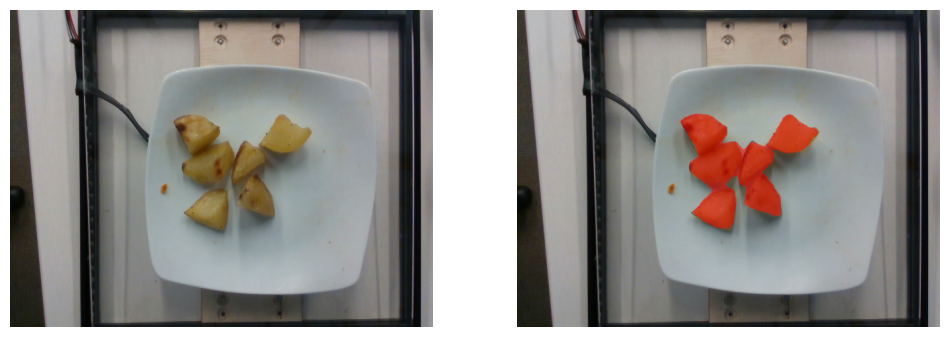

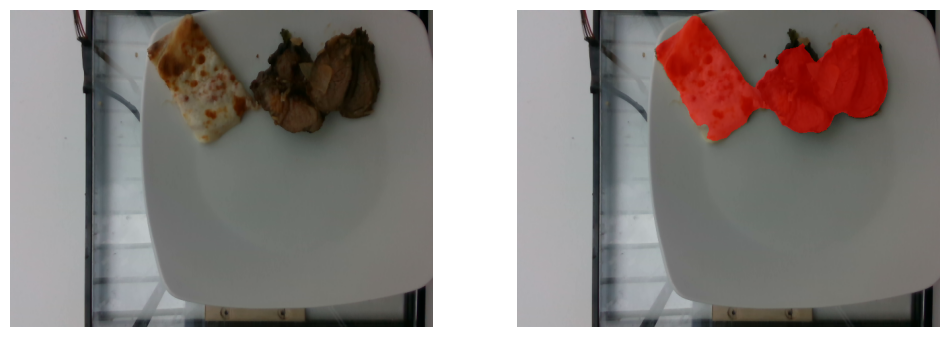

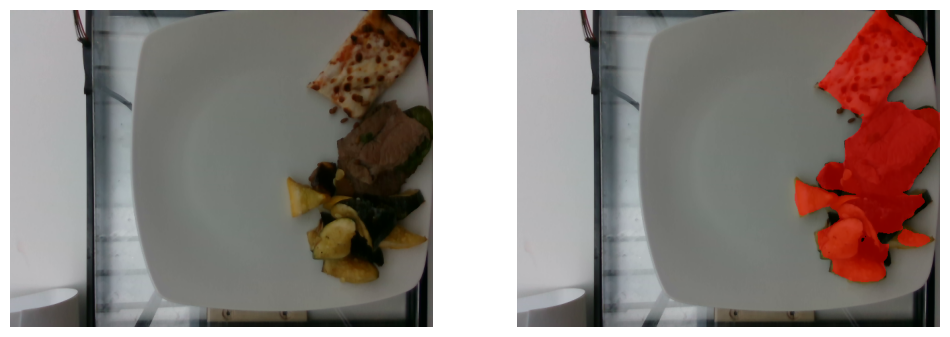

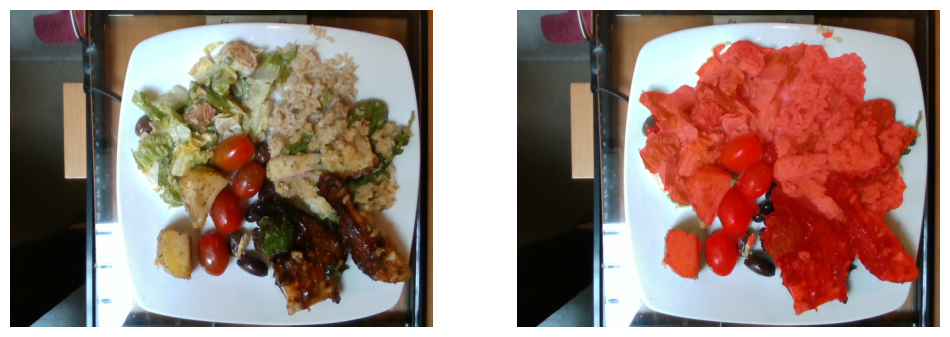

In [59]:
def show_foreground(dish_id):
    pred, fg = foreground_mask(dish_id)
    img = np.array(Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png").convert("RGB"))
    overlay = img.copy()
    overlay[fg] = (0.5 * overlay[fg] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img);     ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].axis("off")
    plt.show()

for i in [0, 45, 75, 90]:
    show_foreground(pilot[i])

In [63]:
from scipy import ndimage      # si falta: %pip install scipy

MIN_AREA   = 400    # píxeles; regiones más pequeñas se descartan
FG_OVERLAP = 0.8    # fracción mínima de una máscara de SAM que debe caer sobre comida

def candidate_regions(dish_id):
    _, sam_masks = auto_masks(dish_id)
    pred, fg = foreground_mask(dish_id)

    regions = []
    covered = np.zeros_like(fg)

    # 1. Máscaras de SAM sobre comida, de pequeña a grande
    for m in sorted(sam_masks, key=lambda m: m.sum()):
        area = m.sum()
        if area < MIN_AREA:
            continue
        if (m & fg).sum() / area < FG_OVERLAP:
            continue
        m = m & fg & ~covered          # recorta al primer plano y evita solapes
        if m.sum() < MIN_AREA:
            continue
        regions.append({"mask": m, "source": "sam"})
        covered |= m

    # 2. y 3. Residual, partido por la clase de B1
    residual = fg & ~covered
    for c in np.unique(pred[residual]):
        comp, n = ndimage.label(residual & (pred == c))
        for k in range(1, n + 1):
            m = comp == k
            if m.sum() >= MIN_AREA:
                regions.append({"mask": m, "source": "residual", "b1_class": int(c)})
    return regions, fg

regiones: 6 (SAM: 6, residual: 0)
comida sin región: 6.1%
ingredientes: {'potatoes': 74.0}


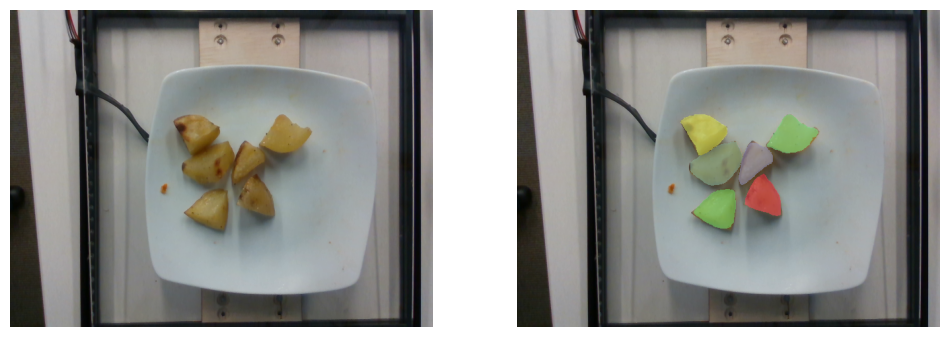

regiones: 3 (SAM: 1, residual: 2)
comida sin región: 1.5%
ingredientes: {'cheese pizza': 39.0, 'beef': 82.468979, 'millet': 10.995864}
  residual: B1 dice 'clase_46', área=6390
  residual: B1 dice 'clase_47', área=14103


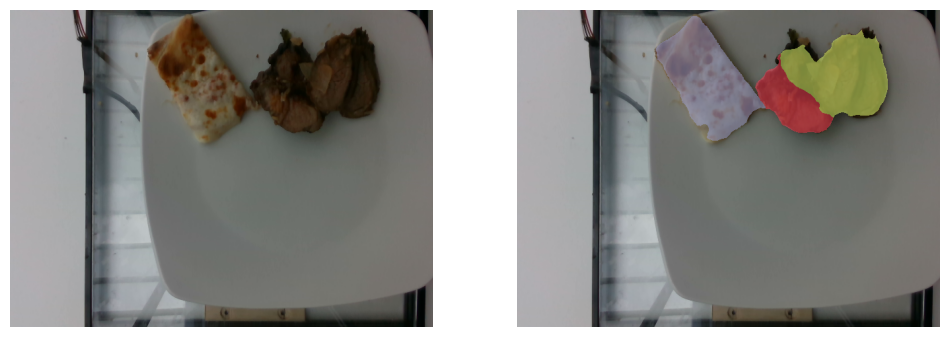

regiones: 9 (SAM: 5, residual: 4)
comida sin región: 4.4%
ingredientes: {'zucchini': 45.5, 'cheese pizza': 35.0, 'beef': 57.270126, 'chayote squash': 45.5}
  residual: B1 dice 'clase_40', área=618
  residual: B1 dice 'clase_46', área=2145
  residual: B1 dice 'clase_82', área=2731
  residual: B1 dice 'clase_89', área=3656


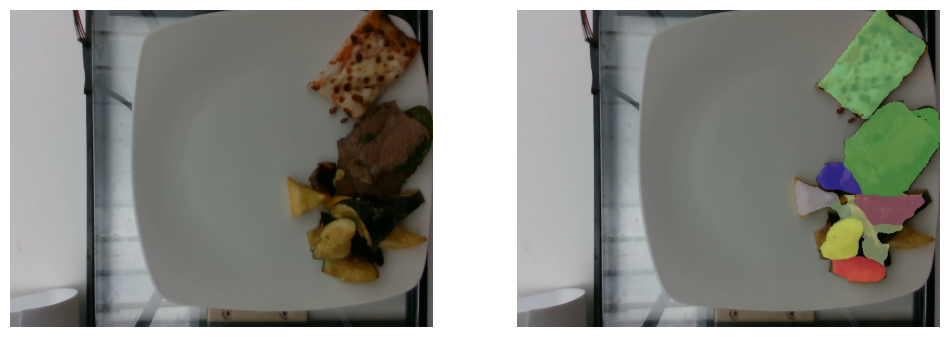

regiones: 18 (SAM: 7, residual: 11)
comida sin región: 3.2%
ingredientes: {'chicken': 124.987068, 'tomatillo': 10.529801, 'roasted potatoes': 53.0, 'olives': 15.0, 'caesar salad': 77.0, 'quinoa': 21.059603, 'fish': 105.298012, 'tomatoes': 95.0, 'rice': 12.498706}
  residual: B1 dice 'clase_48', área=958
  residual: B1 dice 'clase_48', área=1340
  residual: B1 dice 'clase_48', área=34801
  residual: B1 dice 'clase_54', área=418
  residual: B1 dice 'clase_54', área=4661
  residual: B1 dice 'clase_66', área=16550
  residual: B1 dice 'clase_66', área=1185
  residual: B1 dice 'clase_80', área=28029
  residual: B1 dice 'clase_80', área=2027
  residual: B1 dice 'clase_80', área=2343
  residual: B1 dice 'clase_89', área=950


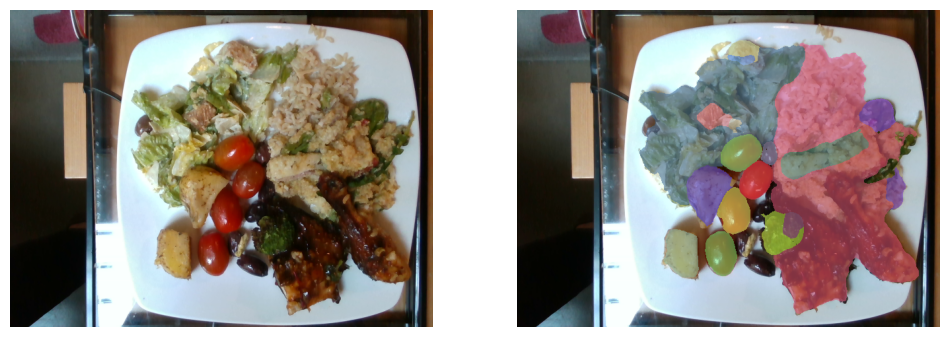

In [65]:
def show_regions(dish_id):
    regs, fg = candidate_regions(dish_id)
    img = np.array(Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png").convert("RGB"))
    overlay = img.astype(float)
    rng = np.random.default_rng(1)
    for r in regs:
        color = rng.integers(60, 255, 3)
        overlay[r["mask"]] = 0.45 * overlay[r["mask"]] + 0.55 * color

    assigned = np.zeros_like(fg)
    for r in regs:
        assigned |= r["mask"]

    n_sam = sum(r["source"] == "sam" for r in regs)
    print(f"regiones: {len(regs)} (SAM: {n_sam}, residual: {len(regs) - n_sam})")
    print(f"comida sin región: {(fg & ~assigned).sum() / fg.sum():.1%}")
    print("ingredientes:", segmentable(dish_id))
    for r in regs:
        if r["source"] == "residual":
            c = r["b1_class"]
            print(f"  residual: B1 dice '{seg.config.id2label.get(c, c)}', área={r['mask'].sum()}")

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img);                      ax[0].axis("off")
    ax[1].imshow(overlay.astype(np.uint8)); ax[1].axis("off")
    plt.show()

for i in [0, 45, 75, 90]:
    show_regions(pilot[i])

In [71]:
from transformers import CLIPModel, CLIPProcessor

clip_name = "openai/clip-vit-large-patch14"      # ~1.7 GB la primera vez
clip_model = CLIPModel.from_pretrained(clip_name).to(device).eval()
clip_proc  = CLIPProcessor.from_pretrained(clip_name)

# Nombres más naturales para CLIP (ajusta según lo que veas)
PROMPT_NAME = {
    "rice": "cooked rice",
    "leafy greens": "leafy salad greens",
    "wheat berry": "cooked wheat berries",
}
REJECT = ["an empty white plate", "a sauce stain", "a metal tray"]

def crop_region(img, mask, pad=10):
    ys, xs = np.where(mask)
    y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, img.shape[0])
    x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, img.shape[1])
    crop = img[y0:y1, x0:x1].copy()
    crop[~mask[y0:y1, x0:x1]] = 127            # fuera de la región: gris neutro
    return Image.fromarray(crop)

@torch.no_grad()
def classify_regions(dish_id, regions):
    img = np.array(Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png").convert("RGB"))
    labels = list(segmentable(dish_id).keys())
    texts = [f"a photo of {PROMPT_NAME.get(l, l)}, a type of food" for l in labels] \
          + [f"a photo of {r}" for r in REJECT]

    crops = [crop_region(img, r["mask"]) for r in regions]
    inputs = clip_proc(text=texts, images=crops, return_tensors="pt", padding=True).to(device)

    out = clip_model(**inputs)
    probs = out.logits_per_image.softmax(dim=-1).cpu().numpy()   # (n_regiones, n_textos)
    return labels, probs

Loading weights: 100%|██████████| 590/590 [00:01<00:00, 455.79it/s] 


ingredientes: {'potatoes': 74.0}


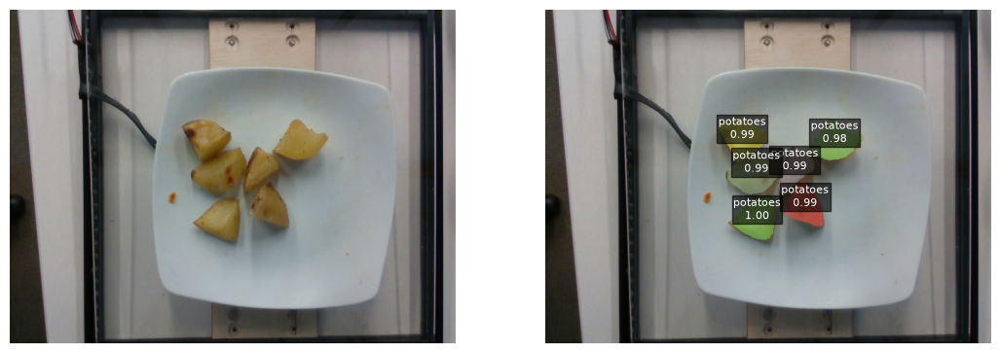

ingredientes: {'cheese pizza': 39.0, 'beef': 82.468979, 'millet': 10.995864}


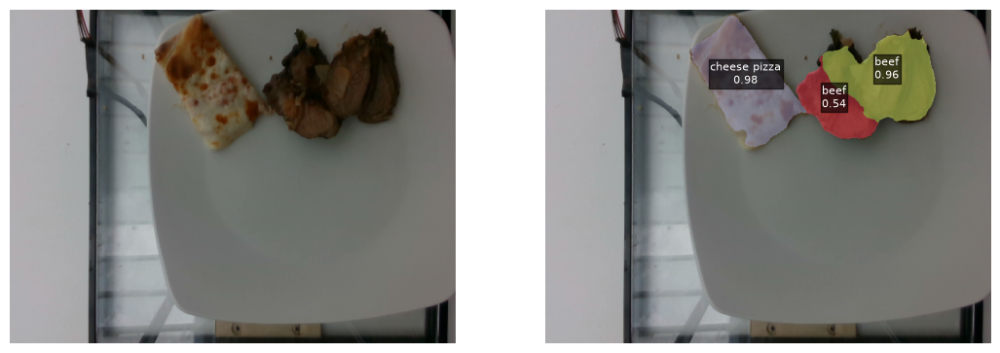

ingredientes: {'zucchini': 45.5, 'cheese pizza': 35.0, 'beef': 57.270126, 'chayote squash': 45.5}


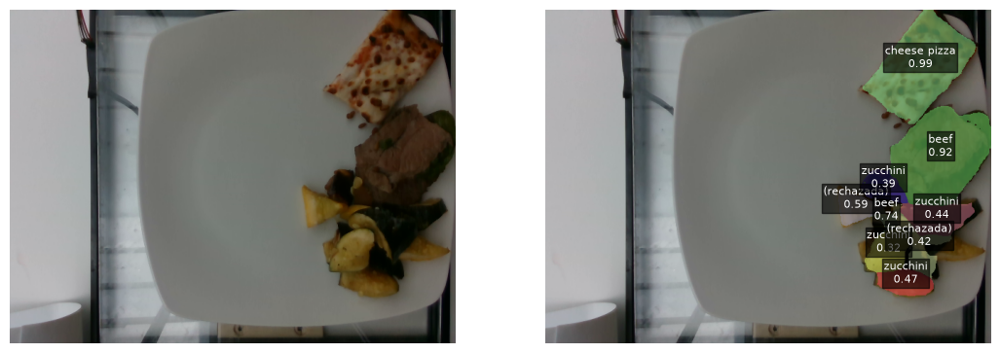

ingredientes: {'chicken': 124.987068, 'tomatillo': 10.529801, 'roasted potatoes': 53.0, 'olives': 15.0, 'caesar salad': 77.0, 'quinoa': 21.059603, 'fish': 105.298012, 'tomatoes': 95.0, 'rice': 12.498706}


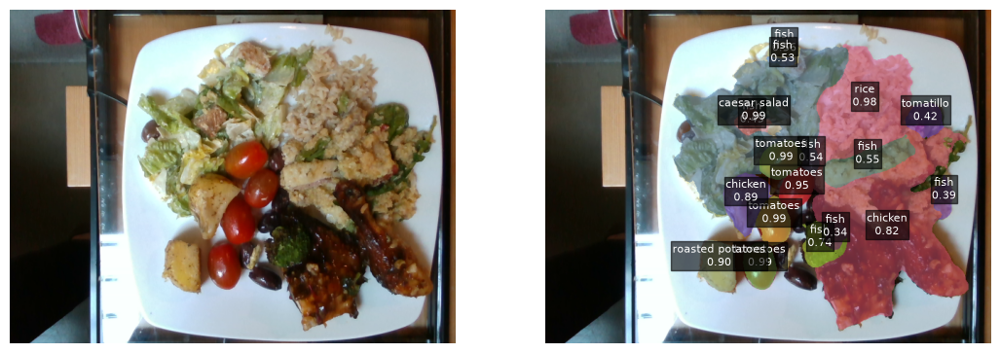

In [72]:
def show_labeled(dish_id):
    regs, fg = candidate_regions(dish_id)
    labels, probs = classify_regions(dish_id, regs)
    img = np.array(Image.open(ROOT / "realsense_overhead" / dish_id / "rgb.png").convert("RGB"))

    print("ingredientes:", segmentable(dish_id))
    fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
    ax[0].imshow(img); ax[0].axis("off")
    overlay = img.astype(float)
    rng = np.random.default_rng(1)
    ax[1].axis("off")
    for r, p in zip(regs, probs):
        k = int(p.argmax())
        name = labels[k] if k < len(labels) else "(rechazada)"
        color = rng.integers(60, 255, 3)
        overlay[r["mask"]] = 0.5 * overlay[r["mask"]] + 0.5 * color
        r["label"], r["prob"] = name, float(p[k])
    ax[1].imshow(overlay.astype(np.uint8))
    for r in regs:
        ys, xs = np.where(r["mask"])
        ax[1].text(xs.mean(), ys.mean(), f'{r["label"]}\n{r["prob"]:.2f}',
                   color="white", fontsize=8, ha="center",
                   bbox=dict(facecolor="black", alpha=0.6, pad=1))
    plt.show()

for i in [0, 45, 75, 90]:
    show_labeled(pilot[i])

In [73]:
CLASS_NAMES = sorted(label_freq)                         # las clases que ya contaste
CLASS_ID = {n: i + 1 for i, n in enumerate(CLASS_NAMES)}  # 0 queda para el fondo
IGNORE = 255

def label_dish(dish_id, thr=0.7, min_area=1500):
    regs, fg = candidate_regions(dish_id)
    labels, probs = classify_regions(dish_id, regs)

    sem = np.zeros(fg.shape, dtype=np.uint8)    # 0 = fondo
    sem[fg] = IGNORE                            # toda la comida empieza como "ignorar"
    for r, p in zip(regs, probs):
        k = int(p.argmax())
        if k >= len(labels):                    # ganó una opción de rechazo
            continue
        if p[k] < thr or r["mask"].sum() < min_area:
            continue
        sem[r["mask"]] = CLASS_ID[labels[k]]    # solo se etiqueta lo seguro
    return sem

In [74]:
import time
stats, t0 = {}, time.time()
for d in pilot:
    regs, fg = candidate_regions(d)
    labels, probs = classify_regions(d, regs)
    rows = []
    for r, p in zip(regs, probs):
        k = int(p.argmax())
        name = labels[k] if k < len(labels) else "(rechazo)"
        rows.append((name, float(p[k]), int(r["mask"].sum())))
    stats[d] = (rows, int(fg.sum()))
print(f"{time.time() - t0:.0f} s para {len(pilot)} platos")

total_food = sum(f for _, f in stats.values())
for thr in [0.5, 0.7, 0.9]:
    ok = sum(a for rows, _ in stats.values() for n, p, a in rows
             if p >= thr and n != "(rechazo)")
    print(f"umbral {thr}: {ok / total_food:.1%} de la comida queda etiquetada")

256 s para 96 platos
umbral 0.5: 82.1% de la comida queda etiquetada
umbral 0.7: 68.6% de la comida queda etiquetada
umbral 0.9: 54.6% de la comida queda etiquetada


9
ingredientes: {'salmon': 97.189484, 'green beans': 58.5, 'rice': 19.437897}


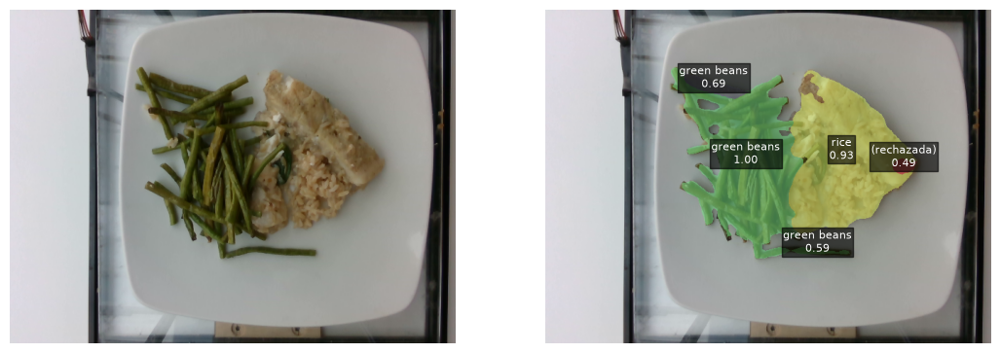

ingredientes: {'rice': 129.0, 'carrot': 34.504005}


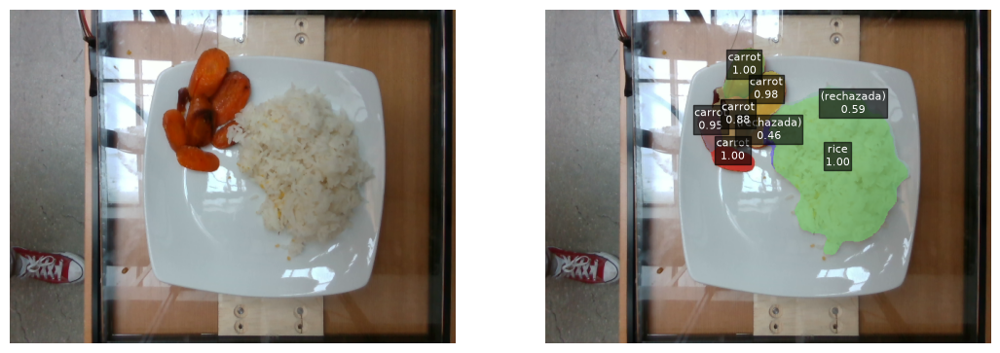

ingredientes: {'zucchini': 56.0, 'broccoli': 56.0, 'salmon': 204.242538, 'rice': 40.848511, 'squash': 56.0}


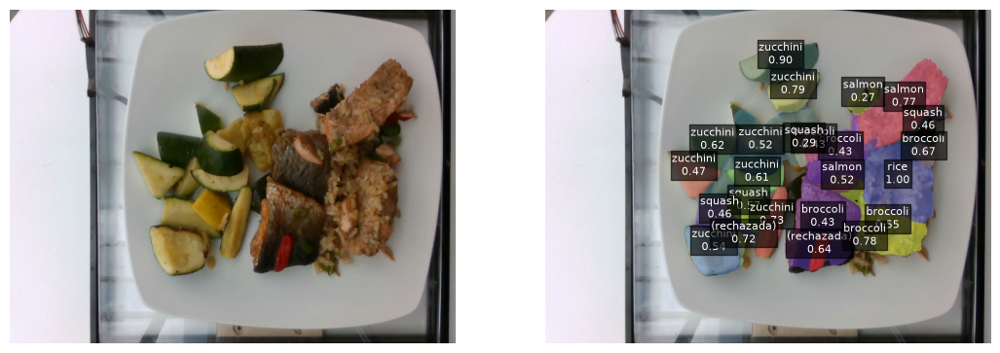

ingredientes: {'rice': 17.0, 'grapes': 37.0, 'cherry tomatoes': 72.0, 'leafy greens': 13.0}


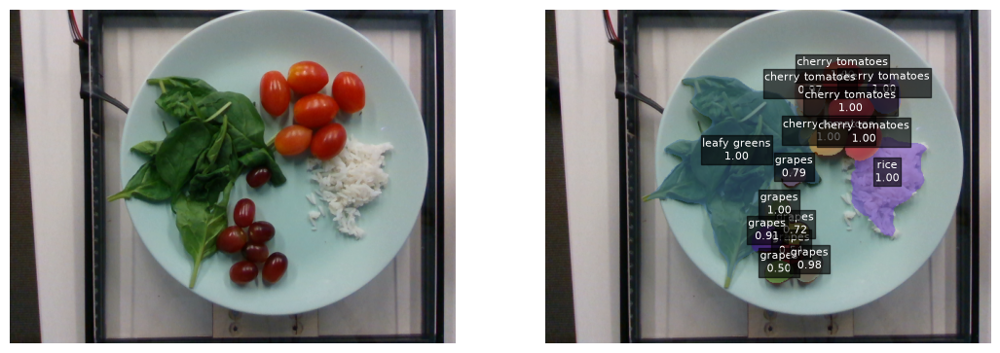

ingredientes: {'leafy greens': 74.871427, 'chicken': 31.651831, 'rice': 14.892601, 'pork': 104.248215, 'mustard greens': 21.540388, 'corn on the cob': 55.0, 'chickpeas': 86.161552}


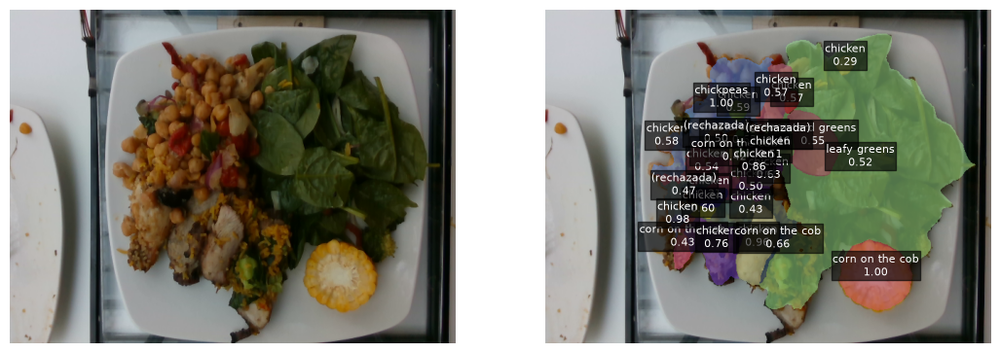

ingredientes: {'chicken': 124.987068, 'tomatillo': 10.529801, 'roasted potatoes': 53.0, 'olives': 15.0, 'caesar salad': 77.0, 'quinoa': 21.059603, 'fish': 105.298012, 'tomatoes': 95.0, 'rice': 12.498706}


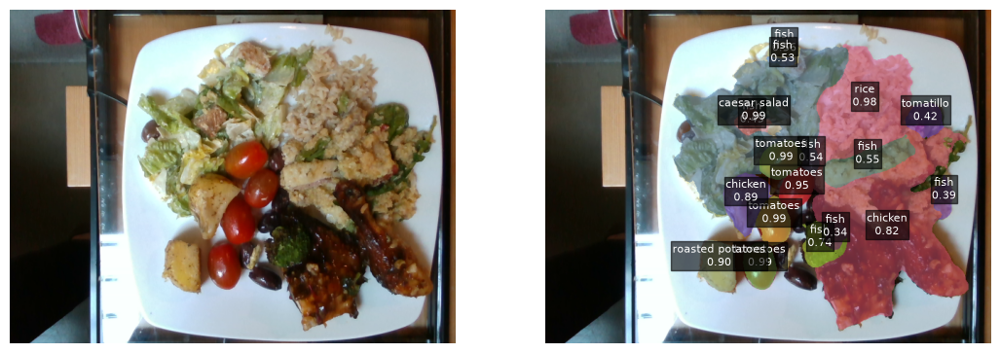

In [75]:
rice_dishes = [d for d in pilot if "rice" in segmentable(d)]
print(len(rice_dishes))
for d in rice_dishes[:6]:
    show_labeled(d)

In [76]:
import matplotlib
matplotlib.use("Agg")          # guarda sin abrir ventanas
out = Path("revision"); out.mkdir(exist_ok=True)

for d in rice_dishes[:10] + pilot[::8]:
    regs, fg = candidate_regions(d)
    labels, probs = classify_regions(d, regs)
    img = np.array(Image.open(ROOT / "realsense_overhead" / d / "rgb.png").convert("RGB"))
    fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
    ax[0].imshow(img); ax[0].axis("off")
    ax[1].imshow(img); ax[1].axis("off")
    for r, p in zip(regs, probs):
        k = int(p.argmax())
        if k >= len(labels) or p[k] < 0.7:
            continue
        ax[1].contour(r["mask"], levels=[0.5], colors="yellow", linewidths=1)
        ys, xs = np.where(r["mask"])
        ax[1].text(xs.mean(), ys.mean(), f"{labels[k]} {p[k]:.2f}", color="white",
                   fontsize=8, ha="center", bbox=dict(facecolor="black", alpha=0.6, pad=1))
    ax[0].set_title(", ".join(f"{n} {g:.0f}g" for n, g in segmentable(d).items()), fontsize=8)
    fig.savefig(out / f"{d}.png", dpi=90, bbox_inches="tight")
    plt.close(fig)

In [77]:
from collections import defaultdict
cov_class = defaultdict(lambda: [0, 0])      # clase -> [px etiquetados, px totales]
for rows, _ in stats.values():
    for n, p, a in rows:
        if n == "(rechazo)":
            continue
        cov_class[n][1] += a
        if p >= 0.7:
            cov_class[n][0] += a
for n, (ok, tot) in sorted(cov_class.items(), key=lambda x: -x[1][1])[:15]:
    print(f"{n:22s} {ok / tot:5.0%} etiquetado   ({tot} px propuestos)")

leafy greens             85% etiquetado   (611297 px propuestos)
broccoli                 72% etiquetado   (384300 px propuestos)
chicken                  66% etiquetado   (244788 px propuestos)
caesar salad             76% etiquetado   (220414 px propuestos)
cheese pizza            100% etiquetado   (207477 px propuestos)
beef                     79% etiquetado   (166192 px propuestos)
lettuce                  29% etiquetado   (162761 px propuestos)
carrot                   98% etiquetado   (142068 px propuestos)
rice                     99% etiquetado   (112895 px propuestos)
pepperoni pizza          54% etiquetado   (105163 px propuestos)
scrambled eggs          100% etiquetado   (90192 px propuestos)
chicken thighs           69% etiquetado   (84320 px propuestos)
squash                   40% etiquetado   (83283 px propuestos)
waffles                 100% etiquetado   (83253 px propuestos)
green beans              97% etiquetado   (74932 px propuestos)


In [79]:
import random, time, traceback

out_dir = Path("raw_labels"); out_dir.mkdir(exist_ok=True)

def save_raw(dish_id):
    regs, fg = candidate_regions(dish_id)
    if regs:
        labels, probs = classify_regions(dish_id, regs)
    else:                                             # plato sin regiones candidatas
        labels, probs = list(segmentable(dish_id).keys()), np.zeros((0, 1))
    region_map = np.zeros(fg.shape, dtype=np.uint8)   # 0 = sin región
    for i, r in enumerate(regs, start=1):
        region_map[r["mask"]] = i
    np.savez_compressed(out_dir / f"{dish_id}.npz",
                        region_map=region_map, fg=fg, probs=probs,
                        labels=np.array(labels))

todo = [d for d in usable if segmentable(d)]          # quita los platos sin clases
random.Random(0).shuffle(todo)
todo = [d for d in todo if not (out_dir / f"{d}.npz").exists()]
print(len(todo), "platos por procesar")

t0, errors = time.time(), []
for n, d in enumerate(todo, start=1):
    try:
        save_raw(d)
    except Exception:
        errors.append((d, traceback.format_exc()))
    if n % 50 == 0:
        torch.cuda.empty_cache()
        rate = (time.time() - t0) / n
        print(f"{n}/{len(todo)} | {rate:.1f} s/plato | faltan ~{rate * (len(todo) - n) / 60:.0f} min | errores: {len(errors)}")

print("terminado; errores:", len(errors))

3470 platos por procesar
50/3470 | 2.8 s/plato | faltan ~159 min | errores: 0
100/3470 | 2.8 s/plato | faltan ~158 min | errores: 0
150/3470 | 21.1 s/plato | faltan ~1170 min | errores: 0
200/3470 | 16.6 s/plato | faltan ~903 min | errores: 0
250/3470 | 16.2 s/plato | faltan ~871 min | errores: 0
300/3470 | 14.0 s/plato | faltan ~739 min | errores: 0
350/3470 | 12.4 s/plato | faltan ~644 min | errores: 0
400/3470 | 11.2 s/plato | faltan ~572 min | errores: 0
450/3470 | 15.5 s/plato | faltan ~779 min | errores: 0
500/3470 | 14.2 s/plato | faltan ~703 min | errores: 0
550/3470 | 19.1 s/plato | faltan ~930 min | errores: 0
600/3470 | 17.7 s/plato | faltan ~848 min | errores: 0
650/3470 | 16.6 s/plato | faltan ~779 min | errores: 0
700/3470 | 15.6 s/plato | faltan ~720 min | errores: 0
750/3470 | 14.7 s/plato | faltan ~668 min | errores: 0
800/3470 | 14.0 s/plato | faltan ~622 min | errores: 0


KeyboardInterrupt: 

In [82]:
bad = []
for f in out_dir.glob("*.npz"):
    try:
        with np.load(f) as z:
            _ = z["region_map"], z["probs"]
    except Exception:
        bad.append(f)
for f in bad:
    f.unlink()
print(len(list(out_dir.glob("*.npz"))), "válidos;", len(bad), "borrados")

849 válidos; 0 borrados


# **Analisis de las imagenes etiquetadas**

In [83]:
THR, MIN_AREA, MARGIN = 0.7, 1500, 0.0

def dish_regions(dish_id, thr=THR, min_area=MIN_AREA, margin=MARGIN):
    z = np.load(out_dir / f"{dish_id}.npz")
    region_map, fg, probs = z["region_map"], z["fg"], z["probs"]
    labels = [str(l) for l in z["labels"]]
    areas = np.bincount(region_map.ravel(), minlength=len(probs) + 1)[1:]   # píxeles por región

    out = []
    for p, a in zip(probs, areas):
        order = np.argsort(p)[::-1]
        k = int(order[0])
        gap = float(p[k] - p[order[1]]) if len(p) > 1 else 1.0   # distancia a la segunda opción
        name = labels[k] if k < len(labels) else None            # None = ganó una opción de rechazo
        ok = name is not None and p[k] >= thr and a >= min_area and gap >= margin
        out.append(dict(label=name, prob=float(p[k]), gap=gap, area=int(a), accepted=ok))
    return out, int(fg.sum())

In [84]:
import pandas as pd      # si falta: %pip install pandas

done = sorted(f.stem for f in out_dir.glob("*.npz"))
rows_dish, rows_reg = [], []
for d in done:
    regs, food = dish_regions(d)
    lab = sum(r["area"] for r in regs if r["accepted"])
    rows_dish.append(dict(dish=d, food_px=food,
                          labeled_frac=lab / food if food else 0.0,
                          n_regions=len(regs),
                          n_accepted=sum(r["accepted"] for r in regs)))
    rows_reg += [dict(dish=d, **r) for r in regs]

dishes_df, regs_df = pd.DataFrame(rows_dish), pd.DataFrame(rows_reg)
print(len(dishes_df), "platos,", len(regs_df), "regiones")

849 platos, 10708 regiones


In [85]:
print(dishes_df["labeled_frac"].describe())
for lo in [0.1, 0.3, 0.5]:
    print(f"platos con menos de {lo:.0%} etiquetado:", (dishes_df.labeled_frac < lo).sum())
print("platos sin ninguna región aceptada:", (dishes_df.n_accepted == 0).sum())

count    849.000000
mean       0.666759
std        0.286175
min        0.000000
25%        0.495806
50%        0.731377
75%        0.914623
max        1.000000
Name: labeled_frac, dtype: float64
platos con menos de 10% etiquetado: 54
platos con menos de 30% etiquetado: 116
platos con menos de 50% etiquetado: 217
platos sin ninguna región aceptada: 38


In [86]:
acc = regs_df[regs_df.accepted]
by_class = (acc.groupby("label")
               .agg(platos=("dish", "nunique"), regiones=("dish", "size"),
                    pixeles=("area", "sum"), prob_media=("prob", "mean"))
               .sort_values("pixeles", ascending=False))
print(by_class.head(25))
print(len(by_class), "clases con al menos una región aceptada;",
      (by_class.platos >= 30).sum(), "con ≥30 platos")

                  platos  regiones  pixeles  prob_media
label                                                  
leafy greens         158       248  6108145    0.931022
broccoli              80       267  2122692    0.949362
chicken               88       199  1628455    0.903928
cheese pizza          72        92  1367144    0.960073
caesar salad          39        65  1360514    0.907664
scrambled eggs        44        45  1224588    0.957882
egg whites            29        43  1120551    0.923979
carrot                59       248  1119278    0.948409
cauliflower           53       125  1041721    0.947975
bacon                 47        93   882227    0.941139
fish                  44       115   674407    0.871964
pork                  24        37   427322    0.869593
corn on the cob       33        61   419468    0.991306
rice                  20        22   419080    0.970727
beef                  27        42   412052    0.930122
sweet potato          40       139   410995    0

In [87]:
food_total = dishes_df.food_px.sum()
for thr in [0.5, 0.7, 0.9]:
    for margin in [0.0, 0.3]:
        m = (regs_df.label.notna() & (regs_df.prob >= thr)
             & (regs_df.gap >= margin) & (regs_df.area >= MIN_AREA))
        print(f"thr={thr}  margen={margin}: {regs_df[m].area.sum() / food_total:.1%} de la comida etiquetada")

thr=0.5  margen=0.0: 76.5% de la comida etiquetada
thr=0.5  margen=0.3: 72.0% de la comida etiquetada
thr=0.7  margen=0.0: 65.8% de la comida etiquetada
thr=0.7  margen=0.3: 65.8% de la comida etiquetada
thr=0.9  margen=0.0: 51.7% de la comida etiquetada
thr=0.9  margen=0.3: 51.7% de la comida etiquetada


In [99]:
food_total = dishes_df.food_px.sum()
print("con min area de 500 (es lo máximo que se alcanza si se sigue bajando queda en este valor o cercano)")
for thr in [0.5, 0.7, 0.9]:
    for margin in [0.0, 0.3]:
        m = (regs_df.label.notna() & (regs_df.prob >= thr)
             & (regs_df.gap >= margin) & (regs_df.area >= 500))
        print(f"thr={thr}  margen={margin}: {regs_df[m].area.sum() / food_total:.1%} de la comida etiquetada")

con min area de 500 (es lo máximo que se alcanza si se sigue bajando queda en este valor o cercano)
thr=0.5  margen=0.0: 82.2% de la comida etiquetada
thr=0.5  margen=0.3: 77.0% de la comida etiquetada
thr=0.7  margen=0.0: 69.7% de la comida etiquetada
thr=0.7  margen=0.3: 69.7% de la comida etiquetada
thr=0.9  margen=0.0: 53.9% de la comida etiquetada
thr=0.9  margen=0.3: 53.9% de la comida etiquetada


In [100]:
rice_rows = []
for d in done:
    z = np.load(out_dir / f"{d}.npz")
    labels = [str(l) for l in z["labels"]]
    if "rice" not in labels:
        continue
    probs = z["probs"]
    areas = np.bincount(z["region_map"].ravel(), minlength=len(probs) + 1)[1:]
    ri = labels.index("rice")
    for p, a in zip(probs, areas):
        k = int(p.argmax())
        rice_rows.append(dict(dish=d, area=int(a), p_rice=float(p[ri]),
                              top=labels[k] if k < len(labels) else "(rechazo)",
                              p_top=float(p[k])))
rice_df = pd.DataFrame(rice_rows)

big = rice_df[rice_df.area >= 1500]
print(rice_df.dish.nunique(), "platos con rice en la metadata")
print("\nlo que CLIP ganó en las regiones grandes de esos platos:")
print(big.top.value_counts().head(8))
print("\nregiones grandes con p_rice entre 0.2 y 0.7:",
      ((big.p_rice >= 0.2) & (big.p_rice < 0.7)).sum())

66 platos con rice en la metadata

lo que CLIP ganó en las regiones grandes de esos platos:
top
(rechazo)    61
chicken      51
broccoli     40
pork         39
carrot       38
salmon       35
rice         33
fish         23
Name: count, dtype: int64

regiones grandes con p_rice entre 0.2 y 0.7: 24


In [101]:
base  = regs_df.label.notna() & (regs_df.prob >= 0.7) & (regs_df.area >= 1500)
loose = regs_df.label.notna() & (regs_df.prob >= 0.5) & (regs_df.area >= 500)
extra = loose & ~base          # lo que solo entra al aflojar los parámetros

print(f"núcleo: {regs_df[base].area.sum() / food_total:.1%} | "
      f"extra: {regs_df[extra].area.sum() / food_total:.1%} ({extra.sum()} regiones)")

núcleo: 65.8% | extra: 16.4% (3731 regiones)


In [102]:
regs_df["rid"] = regs_df.groupby("dish").cumcount() + 1     # número de región dentro del plato
valid = regs_df.label.notna()
p, a = regs_df.prob, regs_df.area

groups = {
    "nucleo": valid & (p >= 0.7) & (a >= 1500),
    "umbral": valid & (p >= 0.5) & (p < 0.7) & (a >= 1500),
    "area":   valid & (p >= 0.7) & (a >= 500) & (a < 1500),
    "ambos":  valid & (p >= 0.5) & (p < 0.7) & (a >= 500) & (a < 1500),
}
for g, m in groups.items():
    print(f"{g:7s} {regs_df[m].area.sum() / food_total:5.1%} de la comida | "
          f"{m.sum():5d} regiones | área media {regs_df[m].area.mean():6.0f} px")

nucleo  65.8% de la comida |  3545 regiones | área media   8628 px
umbral  10.6% de la comida |   902 regiones | área media   5483 px
area     3.9% de la comida |  1942 regiones | área media    932 px
ambos    1.8% de la comida |   887 regiones | área media    950 px


In [103]:
import math
rng_seed = 0
sample_df = pd.concat([regs_df[m].sample(min(30, m.sum()), random_state=rng_seed).assign(grupo=g)
                       for g, m in groups.items()])
sample_df["correcta"] = ""            # la rellenas tú
sample_df.to_csv("revision_regiones.csv")

def review_sheet(sample, path, ncols=6, pad=40):
    axes = plt.subplots(math.ceil(len(sample) / ncols), ncols,
                        figsize=(4 * ncols, 4 * math.ceil(len(sample) / ncols)))[1]
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (idx, r) in zip(axes, sample.iterrows()):
        z = np.load(out_dir / f"{r.dish}.npz")
        mask = z["region_map"] == r.rid
        img = np.array(Image.open(ROOT / "realsense_overhead" / r.dish / "rgb.png").convert("RGB"))
        ys, xs = np.where(mask)
        y0, y1 = max(ys.min() - pad, 0), min(ys.max() + pad, img.shape[0])
        x0, x1 = max(xs.min() - pad, 0), min(xs.max() + pad, img.shape[1])
        ax.imshow(img[y0:y1, x0:x1])
        ax.contour(mask[y0:y1, x0:x1], levels=[0.5], colors="yellow", linewidths=1.2)
        ingr = ", ".join(str(l) for l in z["labels"])
        ax.set_title(f"#{idx}  {r.label}  {r.prob:.2f}\n{ingr[:45]}", fontsize=8)
    plt.savefig(path, dpi=80, bbox_inches="tight")
    plt.close()

for g in groups:
    review_sheet(sample_df[sample_df.grupo == g], f"revision_{g}.png")

In [104]:
rev = pd.read_csv("revision_regiones.csv", index_col=0, dtype={"correcta": str})
rev = rev[rev.correcta.isin(["1", "0", "m"])]
print(rev.groupby("grupo").correcta.value_counts(normalize=True).unstack().round(2))

Empty DataFrame
Columns: []
Index: []


In [106]:
rev = pd.read_csv("revision_regiones.csv", index_col=0, dtype={"correcta": str})

rev.head()

,dish,label,prob,gap,area,accepted,rid,grupo,correcta
10505,dish_1572291722,chicken,0.917789,0.861758,5429,True,12,nucleo,NaN
10320,dish_1568665012,chicken,0.984095,0.975188,20670,True,5,nucleo,NaN
1090,dish_1558638137,apple,0.999970,0.999942,13294,True,1,nucleo,NaN
4287,dish_1562010315,cabbage,0.820361,0.645689,2003,True,4,nucleo,NaN
8606,dish_1565984434,cauliflower,0.999386,0.999069,15745,True,14,nucleo,NaN
